In [108]:
# Environment and configuration

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/prices.csv")

TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"
PAKOKKU_ID = 1664

In [109]:
# Load and standardize the raw dataset
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Check the notebook working directory and DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

required_columns = {
    "date", "commodity", "market_id", "market",
    "unit", "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

# Keep the target commodity and comparable price observations
rice_df = df[
    (df["commodity"] == TARGET_COMMODITY)
    & (df["unit"] == TARGET_UNIT)
    & (df["pricetype"] == TARGET_PRICE_TYPE)
    & (df["currency"] == TARGET_CURRENCY)
].dropna(subset=["date", "price"]).copy()

rice_df["month"] = rice_df["date"].dt.to_period("M")

# One row per market-month
monthly_rice = (
    rice_df.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observation_count=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

print("Filtered raw observations:", len(rice_df))
print("Monthly market-price rows:", len(monthly_rice))
print("Markets represented:", monthly_rice["market_id"].nunique())

# Select Pakokku and restore its complete monthly calendar
df_pakokku = (
    monthly_rice[monthly_rice["market_id"] == PAKOKKU_ID]
    .sort_values("month")
    .set_index("month")
    .copy()
)

if df_pakokku.empty:
    raise ValueError(f"No rice observations found for market ID {PAKOKKU_ID}.")

full_month_index = pd.period_range(
    start=df_pakokku.index.min(),
    end=df_pakokku.index.max(),
    freq="M"
)

df_pakokku = df_pakokku.reindex(full_month_index)
df_pakokku.index.name = "month"

print("First month:", df_pakokku.index.min())
print("Last month:", df_pakokku.index.max())
print("Calendar months:", len(df_pakokku))
print("Observed price months:", df_pakokku["monthly_price"].notna().sum())
print("Missing months:", df_pakokku["monthly_price"].isna().sum())
print("Coverage (%):", round(df_pakokku["monthly_price"].notna().mean() * 100, 1))

display(
    df_pakokku.loc[
        df_pakokku["monthly_price"].isna(),
        ["monthly_price", "observation_count"]
    ]
)

# Summarize consecutive runs of missing months
missing_periods = df_pakokku.index[df_pakokku["monthly_price"].isna()]

missing_runs = []
if len(missing_periods):
    run_start = previous = missing_periods[0]
    for period in missing_periods[1:]:
        if period == previous + 1:
            previous = period
        else:
            missing_runs.append((run_start, previous))
            run_start = previous = period
    missing_runs.append((run_start, previous))

missing_runs_df = pd.DataFrame(
    [
        {
            "start_month": str(start),
            "end_month": str(end),
            "months_missing": (end - start).n + 1
        }
        for start, end in missing_runs
    ]
)

display(missing_runs_df)

Filtered raw observations: 10231
Monthly market-price rows: 10231
Markets represented: 298
First month: 2014-01
Last month: 2026-09
Calendar months: 153
Observed price months: 146
Missing months: 7
Coverage (%): 95.4


,monthly_price,observation_count
month,,
2015-05,NaN,NaN
2015-06,NaN,NaN
2015-07,NaN,NaN
2019-05,NaN,NaN
2019-06,NaN,NaN
2020-02,NaN,NaN
2025-01,NaN,NaN


,start_month,end_month,months_missing
0,2015-05,2015-07,3
1,2019-05,2019-06,2
2,2020-02,2020-02,1
3,2025-01,2025-01,1


In [110]:
# Start with ONLY the original monthly price
df_model = df_pakokku[["monthly_price"]].copy()

# Create lag features: previous 1 to 12 calendar months
for lag in range(1, 13):
    df_model[f"lag_{lag}"] = (
        df_model["monthly_price"].shift(lag)
    )

display(df_model.head(10))

,monthly_price,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12
month,,,,,,,,,,,,,
2014-01,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-02,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-03,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-04,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-05,708.0,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-06,708.0,708.0,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-07,708.0,708.0,708.0,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN,NaN
2014-08,708.0,708.0,708.0,708.0,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN,NaN
2014-09,755.0,708.0,708.0,708.0,708.0,712.0,693.0,693.0,693.0,NaN,NaN,NaN,NaN


In [111]:
# Shift first to exclude the current month's target price
history = df_model["monthly_price"].shift(1)

for window in [3, 6, 12]:
    df_model[f"rolling_mean_{window}"] = (
        history.rolling(
            window=window,
            min_periods=window
        ).mean()
    )

In [112]:

print("Dataset shape:", df_model.shape)

print("\nMissing values per column:")
display(df_model.isna().sum())

print(
    "\nAvailable target observations:",
    df_model["monthly_price"].notna().sum()
)

Dataset shape: (153, 16)

Missing values per column:


monthly_price       7
lag_1               8
lag_2               9
lag_3              10
lag_4              11
lag_5              12
lag_6              13
lag_7              14
lag_8              15
lag_9              16
lag_10             17
lag_11             18
lag_12             19
rolling_mean_3     18
rolling_mean_6     33
rolling_mean_12    59
dtype: int64


Available target observations: 146


For example:
- lag_1 has 8 missing values: 7 original missing prices + 1 initial month without a previous month.
- lag_12 has 19 missing values: the original missing prices plus the first 12 months without sufficient history.
- rolling_mean_12 has 59 missing values because a complete 12-month historical window is required, and even one missing month makes that window incomplete.

In [113]:
# Count rows with complete features and target
complete_mask = df_model.notna().all(axis=1)

print("Total rows:", len(df_model))
print("Complete rows:", complete_mask.sum())
print("Rows with missing values:", (~complete_mask).sum())

# Check missingness by year
missing_by_year = (
    df_model.isna()
    .groupby(df_model.index.year)
    .sum()
)

display(missing_by_year)

Total rows: 153
Complete rows: 91
Rows with missing values: 62


,monthly_price,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12
month,,,,,,,,,,,,,,,,
2014,0,1,2,3,4,5,6,7,8,9,10,11,12,3,6,12
2015,3,3,3,3,3,3,2,1,0,0,0,0,0,5,7,7
2016,0,0,0,0,0,0,1,2,3,3,3,3,3,0,1,7
2017,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2018,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2019,2,2,2,2,2,2,2,1,0,0,0,0,0,4,7,7
2020,1,1,1,1,1,1,1,2,3,3,3,2,2,3,6,12
2021,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,2
2022,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [114]:
# Target: current month's actual price
target = "monthly_price"

# Features: historical information only
feature_cols = [
    col for col in df_model.columns
    if col != target
]

# Keep rows where the target and all selected features are available
df_ready = df_model.dropna(
    subset=[target] + feature_cols
).copy()

X = df_ready[feature_cols]
y = df_ready[target]

print("Original rows:", len(df_model))
print("Usable rows:", len(df_ready))
print("Removed rows:", len(df_model) - len(df_ready))

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

display(df_ready.head())
display(df_ready.tail())

Original rows: 153
Usable rows: 91
Removed rows: 62

Feature shape: (91, 15)
Target shape: (91,)


,monthly_price,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12
month,,,,,,,,,,,,,,,,
2015-01,684.0,708.0,755.0,755.0,755.0,708.0,708.0,708.0,708.0,712.0,693.0,693.0,693.0,739.333333,731.500000,716.333333
2015-02,684.0,684.0,708.0,755.0,755.0,755.0,708.0,708.0,708.0,708.0,712.0,693.0,693.0,715.666667,727.500000,715.583333
2015-03,684.0,684.0,684.0,708.0,755.0,755.0,755.0,708.0,708.0,708.0,708.0,712.0,693.0,692.000000,723.500000,714.833333
2015-04,684.0,684.0,684.0,684.0,708.0,755.0,755.0,755.0,708.0,708.0,708.0,708.0,712.0,684.000000,711.666667,714.083333
2016-08,825.0,825.0,825.0,790.0,778.0,755.0,741.0,708.0,814.0,802.0,802.0,802.0,802.0,813.333333,785.666667,787.000000


,monthly_price,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12
month,,,,,,,,,,,,,,,,
2026-05,2585.0,1880.0,1786.0,1786.0,1786.0,1770.0,1754.0,2587.0,1723.0,1880.0,1927.0,1880.0,1879.7,1817.333333,1793.666667,1886.558333
2026-06,2726.0,2585.0,1880.0,1786.0,1786.0,1786.0,1770.0,1754.0,2587.0,1723.0,1880.0,1927.0,1880.0,2083.666667,1932.166667,1945.333333
2026-07,2820.0,2726.0,2585.0,1880.0,1786.0,1786.0,1786.0,1770.0,1754.0,2587.0,1723.0,1880.0,1927.0,2397.000000,2091.500000,2015.833333
2026-08,2976.0,2820.0,2726.0,2585.0,1880.0,1786.0,1786.0,1786.0,1770.0,1754.0,2587.0,1723.0,1880.0,2710.333333,2263.833333,2090.250000
2026-09,3086.0,2976.0,2820.0,2726.0,2585.0,1880.0,1786.0,1786.0,1786.0,1770.0,1754.0,2587.0,1723.0,2840.666667,2462.166667,2181.583333


In [115]:
df_compact = df_pakokku[["monthly_price"]].copy()

for lag in [1, 2, 3]:
    df_compact[f"lag_{lag}"] = (
        df_compact["monthly_price"].shift(lag)
    )

history = df_compact["monthly_price"].shift(1)

df_compact["rolling_mean_3"] = (
    history.rolling(window=3, min_periods=3).mean()
)

df_compact_ready = df_compact.dropna().copy()

print("Full feature dataset:", len(df_ready))
print("Compact feature dataset:", len(df_compact_ready))

Full feature dataset: 91
Compact feature dataset: 131


In [116]:
print("Original calendar months:", len(df_model))
print("Original observed prices:",
      df_model["monthly_price"].notna().sum(), "\n")

print("df_ready Rows retained:", len(df_ready))
print("df_ready Retention rate:",
      round(len(df_ready) / len(df_model) * 100, 2), "%\n")


print("df_compact_ready Rows retained:", len(df_compact_ready))
print("df_compact_ready Retention rate:",
      round(len(df_compact_ready) / len(df_model) * 100, 2), "%\n")


Original calendar months: 153
Original observed prices: 146 

df_ready Rows retained: 91
df_ready Retention rate: 59.48 %

df_compact_ready Rows retained: 131
df_compact_ready Retention rate: 85.62 %



In [117]:
print("FULL DATASET")
print("Start:", df_ready.index.min())
print("End:", df_ready.index.max())

print("\nCOMPACT DATASET")
print("Start:", df_compact_ready.index.min())
print("End:", df_compact_ready.index.max())

print("\nCOMMON MONTHS")
common_months = df_ready.index.intersection(
    df_compact_ready.index
)

print("Common observations:", len(common_months))
print("Start:", common_months.min())
print("End:", common_months.max())

FULL DATASET
Start: 2015-01
End: 2026-09

COMPACT DATASET
Start: 2014-04
End: 2026-09

COMMON MONTHS
Common observations: 91
Start: 2015-01
End: 2026-09


Experiment A — Full feature set<br>
**91**<br>
12 lag features + 3 rolling means<br>

Experiment B — Compact feature set<br>
**131**<br>
3 lag features + 1 rolling mean<br>

In [118]:
# Use common months to establish shared evaluation boundaries
common_months = common_months.sort_values()

n = len(common_months)

train_end_idx = int(n * 0.60) - 1
val_end_idx = int(n * 0.80) - 1

train_end_date = common_months[train_end_idx]

val_start_date = common_months[train_end_idx + 1]
val_end_date = common_months[val_end_idx]

test_start_date = common_months[val_end_idx + 1]
test_end_date = common_months[-1]

print("TRAIN ends:", train_end_date)
print("VALIDATION:", val_start_date, "to", val_end_date)
print("TEST:", test_start_date, "to", test_end_date)

TRAIN ends: 2022-07
VALIDATION: 2022-08 to 2024-01
TEST: 2024-02 to 2026-09


In [119]:
def inspect_split(df, name):
    train = df.loc[:train_end_date]
    val = df.loc[val_start_date:val_end_date]
    test = df.loc[test_start_date:test_end_date]

    print(f"\n{name}")
    print("Training:", len(train))
    print("Validation:", len(val))
    print("Testing:", len(test))


inspect_split(df_ready, "FULL FEATURES")
inspect_split(df_compact_ready, "COMPACT FEATURES")


FULL FEATURES
Training: 54
Validation: 18
Testing: 19

COMPACT FEATURES
Training: 85
Validation: 18
Testing: 28


## Experiment 1: Naive Forecasting Baseline

In [120]:
# Restrict both configurations to identical observations
df_full_eval = df_ready.loc[common_months].copy()

df_compact_eval = df_compact_ready.loc[common_months].copy()

# Verify identical observations and target values
assert df_full_eval.index.equals(df_compact_eval.index)

assert np.allclose(
    df_full_eval["monthly_price"],
    df_compact_eval["monthly_price"]
)

print("Full and compact datasets have identical evaluation months.")
print("Number of observations:", len(common_months))

Full and compact datasets have identical evaluation months.
Number of observations: 91


In [121]:
def inspect_final_split(df, name):

    splits = {
        "TRAIN": df.loc[:train_end_date],
        "VALIDATION": df.loc[val_start_date:val_end_date],
        "TEST": df.loc[test_start_date:test_end_date]
    }

    print(f"\n{name}")

    for period, subset in splits.items():
        print(
            f"{period}: {len(subset)} observations | "
            f"{subset.index.min()} to {subset.index.max()}"
        )


inspect_final_split(df_full_eval, "FULL FEATURES")
inspect_final_split(df_compact_eval, "COMPACT FEATURES")


FULL FEATURES
TRAIN: 54 observations | 2015-01 to 2022-07
VALIDATION: 18 observations | 2022-08 to 2024-01
TEST: 19 observations | 2024-02 to 2026-09

COMPACT FEATURES
TRAIN: 54 observations | 2015-01 to 2022-07
VALIDATION: 18 observations | 2022-08 to 2024-01
TEST: 19 observations | 2024-02 to 2026-09


In [122]:
def evaluate_naive_baseline(df, name):

    validation = df.loc[
        val_start_date:val_end_date
    ]

    actual = validation["monthly_price"]
    predicted = validation["lag_1"]

    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    print(f"\n{name}")
    print("Observations:", len(validation))
    print("MAE:", round(mae, 2), "MMK/KG")
    print("RMSE:", round(rmse, 2), "MMK/KG")

    return {
        "model": "Naive",
        "configuration": name,
        "observations": len(validation),
        "MAE": mae,
        "RMSE": rmse
    }


baseline_results = pd.DataFrame([
    evaluate_naive_baseline(
        df_full_eval, "Full features"
    ),
    evaluate_naive_baseline(
        df_compact_eval, "Compact features"
    )
])

display(baseline_results)


Full features
Observations: 18
MAE: 124.91 MMK/KG
RMSE: 158.57 MMK/KG

Compact features
Observations: 18
MAE: 124.91 MMK/KG
RMSE: 158.57 MMK/KG


,model,configuration,observations,MAE,RMSE
0,Naive,Full features,18,124.905556,158.574259
1,Naive,Compact features,18,124.905556,158.574259


In [123]:
# Create a baseline dataset from original monthly prices
baseline_df = df_pakokku[["monthly_price"]].copy()

# Predict the current month using the previous month's actual price
baseline_df["naive_prediction"] = (
    baseline_df["monthly_price"].shift(1)
)

# Select validation period
baseline_val = baseline_df.loc[
    val_start_date:val_end_date
].copy()

# Restrict to common evaluation observations
baseline_val = baseline_val.loc[
    baseline_val.index.isin(common_months)
]

# Keep valid actual/predicted pairs
baseline_val = baseline_val.dropna(
    subset=["monthly_price", "naive_prediction"]
)

# Calculate evaluation metrics
actual = baseline_val["monthly_price"]
predicted = baseline_val["naive_prediction"]

mae = np.mean(np.abs(actual - predicted))
rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print("NAIVE BASELINE — VALIDATION")
print("Observations:", len(baseline_val))
print("MAE:", round(mae, 2), "MMK/KG")
print("RMSE:", round(rmse, 2), "MMK/KG")



NAIVE BASELINE — VALIDATION
Observations: 18
MAE: 124.91 MMK/KG
RMSE: 158.57 MMK/KG


RMSE is higher than MAE, which suggests some larger errors have a greater influence on our evaluation.

In [124]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error


def evaluate_model(df, model, model_name, config_name):

    train = df.loc[:train_end_date]
    val = df.loc[val_start_date:val_end_date]

    X_train = train.drop(columns=["monthly_price"])
    y_train = train["monthly_price"]

    X_val = val.drop(columns=["monthly_price"])
    y_val = val["monthly_price"]

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    return {
        "model": model_name,
        "configuration": config_name,
        "observations": len(y_val),
        "MAE": mae,
        "RMSE": rmse
    }


results = []

datasets = {
    "Full": df_full_eval,
    "Compact": df_compact_eval
}

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1.0)
}

for config_name, dataset in datasets.items():

    for model_name, estimator in models.items():

        model = make_pipeline(
            StandardScaler(),
            estimator
        )

        result = evaluate_model(
            dataset,
            model,
            model_name,
            config_name
        )

        results.append(result)


model_results = pd.DataFrame(results)

display(
    model_results.sort_values("RMSE")
)

,model,configuration,observations,MAE,RMSE
0,Linear Regression,Full,18,190.705358,235.579831
1,Ridge (alpha=1),Full,18,200.261135,244.420417
2,Linear Regression,Compact,18,198.143073,249.994496
3,Ridge (alpha=1),Compact,18,205.637245,257.382814


Look at this:
- Full Linear Regression has an MAE approximately 52.7% higher than the naïve baseline.
- Compact Linear Regression has an MAE approximately 58.6% higher.
- Ridge with compact features performs worst.
Our best ML configuration so far is Full Linear Regression, but it still loses.

In [125]:
# Prepare training and validation datasets
train = df_full_eval.loc[:train_end_date]

val = df_full_eval.loc[
    val_start_date:val_end_date
]

# Fit Full Linear Regression
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

X_train = train.drop(columns=["monthly_price"])
y_train = train["monthly_price"]

X_val = val.drop(columns=["monthly_price"])

model.fit(X_train, y_train)

# Generate ML predictions
linear_predictions = model.predict(X_val)

# Compare predictions
comparison = pd.DataFrame(
    {
        "actual_price": val["monthly_price"],
        "naive_prediction": val["lag_1"],
        "linear_prediction": linear_predictions
    },
    index=val.index
)

# Calculate absolute errors
comparison["naive_error"] = (
    comparison["actual_price"]
    - comparison["naive_prediction"]
).abs()

comparison["linear_error"] = (
    comparison["actual_price"]
    - comparison["linear_prediction"]
).abs()

display(comparison.round(2))

,actual_price,naive_prediction,linear_prediction,naive_error,linear_error
month,,,,,
2022-08,915.00,708.00,704.57,207.00,210.43
2022-09,910.00,915.00,890.14,5.00,19.86
2022-10,924.00,910.00,868.72,14.00,55.28
2022-11,939.00,924.00,851.94,15.00,87.06
2022-12,956.00,939.00,904.96,17.00,51.04
2023-01,1034.00,956.00,908.10,78.00,125.90
2023-02,1222.00,1034.00,1003.68,188.00,218.32
2023-03,1190.00,1222.00,1098.63,32.00,91.37
2023-04,1300.00,1190.00,1128.97,110.00,171.03


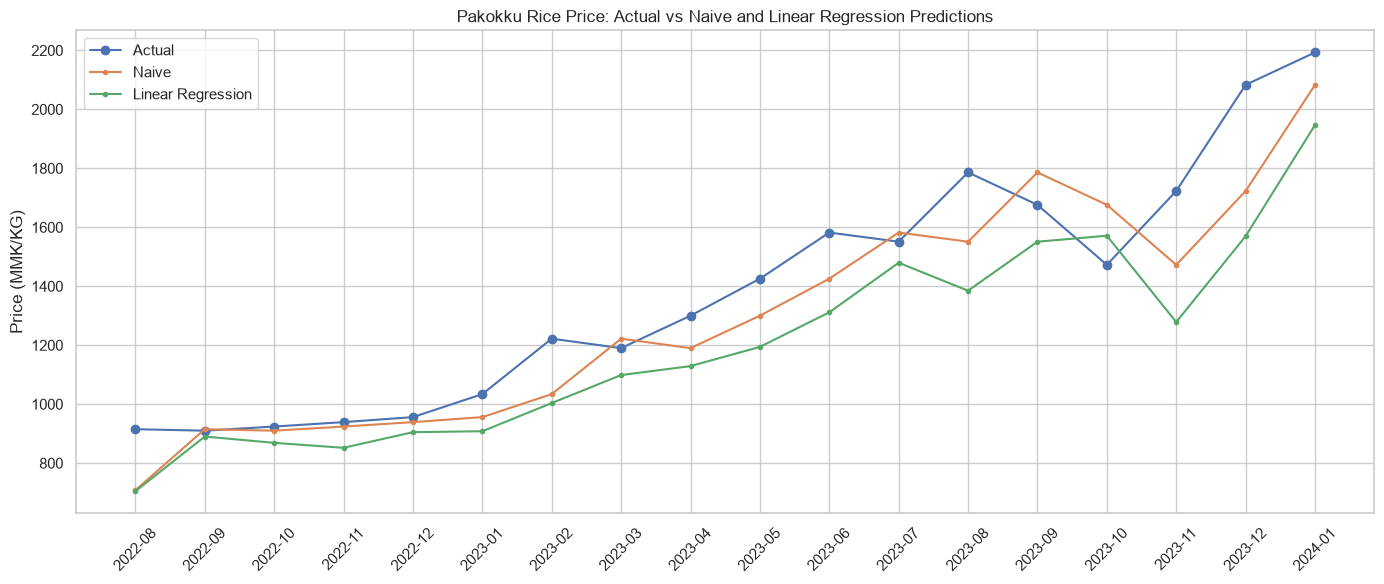

In [126]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparison.index.astype(str),
    comparison["actual_price"],
    marker="o",
    label="Actual"
)

plt.plot(
    comparison.index.astype(str),
    comparison["naive_prediction"],
    marker=".",
    label="Naive"
)

plt.plot(
    comparison.index.astype(str),
    comparison["linear_prediction"],
    marker=".",
    label="Linear Regression"
)

plt.xticks(rotation=45)
plt.ylabel("Price (MMK/KG)")
plt.title("Pakokku Rice Price: Actual vs Naive and Linear Regression Predictions")
plt.legend()
plt.tight_layout()
plt.show()

Our Linear Regression model is struggling to follow the rapid increase in Pakokku rice prices.

In [127]:

# Experiment 2: Alternative forecasting baselines

validation = df_full_eval.loc[
    val_start_date:val_end_date
].copy()

baseline_candidates = {
    "Naive (lag 1)": "lag_1",
    "Seasonal Naive (lag 12)": "lag_12",
    "Moving Average (3)": "rolling_mean_3",
    "Moving Average (6)": "rolling_mean_6",
    "Moving Average (12)": "rolling_mean_12"
}

baseline_comparison = []

for name, prediction_column in baseline_candidates.items():

    actual = validation["monthly_price"]
    predicted = validation[prediction_column]

    valid = actual.notna() & predicted.notna()

    actual_valid = actual[valid]
    predicted_valid = predicted[valid]

    mae = mean_absolute_error(
        actual_valid, predicted_valid
    )

    rmse = np.sqrt(
        mean_squared_error(actual_valid, predicted_valid)
    )

    baseline_comparison.append({
        "baseline": name,
        "observations": len(actual_valid),
        "MAE": mae,
        "RMSE": rmse
    })

baseline_comparison = pd.DataFrame(
    baseline_comparison
).sort_values("RMSE")

display(baseline_comparison.round(2))


,baseline,observations,MAE,RMSE
0,Naive (lag 1),18,124.91,158.57
2,Moving Average (3),18,175.58,214.24
3,Moving Average (6),18,248.44,274.29
4,Moving Average (12),18,394.38,424.77
1,Seasonal Naive (lag 12),18,639.84,696.06


In [128]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Define tree-based models (no StandardScaler needed for trees)
tree_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

tree_results = []

for config_name, dataset in datasets.items():
    for model_name, estimator in tree_models.items():
        result = evaluate_model(
            dataset,
            estimator,
            model_name,
            config_name
        )
        tree_results.append(result)

tree_results_df = pd.DataFrame(tree_results)

# Combine with your previous Naive and Linear results for a unified leaderboard
all_val_results = pd.concat(
    [baseline_results, model_results, tree_results_df],
    ignore_index=True
).sort_values("RMSE")

display(all_val_results)

,model,configuration,observations,MAE,RMSE
0,Naive,Full features,18,124.905556,158.574259
1,Naive,Compact features,18,124.905556,158.574259
2,Linear Regression,Full,18,190.705358,235.579831
3,Ridge (alpha=1),Full,18,200.261135,244.420417
4,Linear Regression,Compact,18,198.143073,249.994496
5,Ridge (alpha=1),Compact,18,205.637245,257.382814
6,Random Forest,Full,18,649.212708,760.258106
8,Random Forest,Compact,18,652.446089,765.359102
9,XGBoost,Compact,18,661.095726,776.820423
7,XGBoost,Full,18,801.248007,939.191557


In [129]:
depth_thresholds = [2, 3, 5, 8, None]
threshold_rows = []

for config_name, dataset in datasets.items():
    for depth in depth_thresholds:
        depth_label = "Unlimited" if depth is None else str(depth)
        
        # Random Forest at depth threshold
        rf = RandomForestRegressor(
            n_estimators=200,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        )
        res_rf = evaluate_model(dataset, rf, "Random Forest", config_name)
        res_rf["max_depth_threshold"] = depth_label
        threshold_rows.append(res_rf)
        
        # XGBoost at depth threshold (XGBoost requires an integer max_depth; 10 approximates unlimited here)
        xgb_depth = 10 if depth is None else depth
        xgb = XGBRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=xgb_depth,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42
        )
        res_xgb = evaluate_model(dataset, xgb, "XGBoost", config_name)
        res_xgb["max_depth_threshold"] = depth_label
        threshold_rows.append(res_xgb)

depth_comparison_df = pd.DataFrame(threshold_rows).sort_values(["configuration", "RMSE"])
display(depth_comparison_df)

# Identify the best configuration + threshold per model
best_per_model = (
    depth_comparison_df
    .sort_values("RMSE")
    .groupby("model", as_index=False)
    .first()
)
print("\nBest Threshold per Model (by Validation RMSE):")
display(best_per_model)

,model,configuration,observations,MAE,RMSE,max_depth_threshold
13,XGBoost,Compact,18,661.095726,776.820423,3
15,XGBoost,Compact,18,662.913733,777.881521,5
17,XGBoost,Compact,18,663.909884,778.486525,8
19,XGBoost,Compact,18,665.063286,779.725829,Unlimited
11,XGBoost,Compact,18,663.775766,780.066609,2
10,Random Forest,Compact,18,688.010808,799.673890,2
18,Random Forest,Compact,18,688.281844,801.085090,Unlimited
16,Random Forest,Compact,18,692.842642,805.634719,8
12,Random Forest,Compact,18,694.287193,807.365093,3
14,Random Forest,Compact,18,697.592123,810.301693,5



Best Threshold per Model (by Validation RMSE):


,model,configuration,observations,MAE,RMSE,max_depth_threshold
0,Random Forest,Compact,18,688.010808,799.673890,2
1,XGBoost,Compact,18,661.095726,776.820423,3


,Model,MAE,RMSE,Within ±50 MMK (%),Within ±100 MMK (%),Within ±150 MMK (%),Within ±200 MMK (%)
0,Naive,124.91,158.57,33.3,38.9,61.1,72.2
1,Linear,190.71,235.58,5.6,38.9,50.0,55.6
2,Random Forest,718.20,837.69,0.0,0.0,0.0,16.7
3,XGBoost,807.85,944.83,0.0,0.0,11.1,22.2


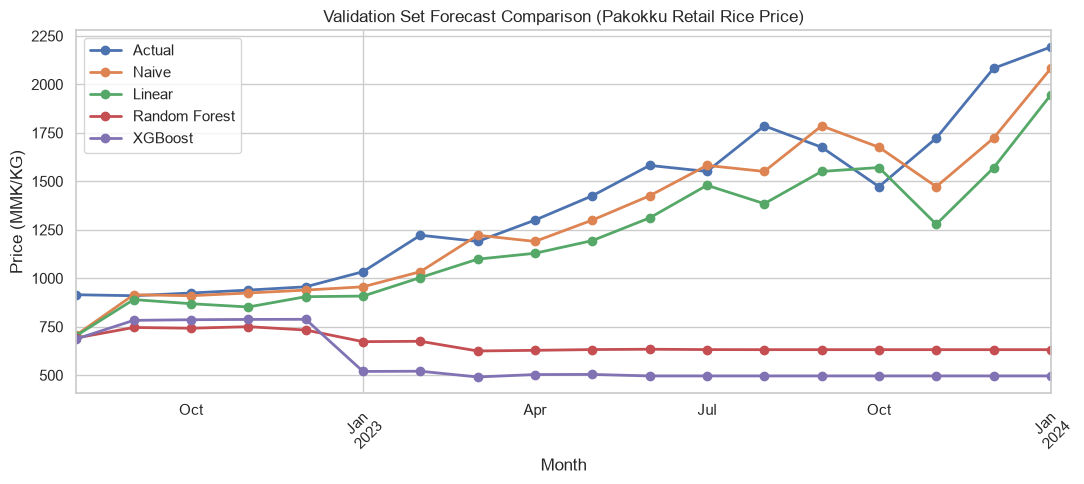

In [130]:
# Fit best RF and XGBoost on Full features to inspect validation predictions
train = df_full_eval.loc[:train_end_date]
val = df_full_eval.loc[val_start_date:val_end_date]

X_train, y_train = train.drop(columns=["monthly_price"]), train["monthly_price"]
X_val, y_val = val.drop(columns=["monthly_price"]), val["monthly_price"]

rf_best = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42).fit(X_train, y_train)
xgb_best = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42).fit(X_train, y_train)

pred_df = pd.DataFrame({
    "Actual": y_val,
    "Naive": val["lag_1"],
    "Linear": linear_predictions,
    "Random Forest": rf_best.predict(X_val),
    "XGBoost": xgb_best.predict(X_val)
}, index=val.index)

# Compare accuracy across MMK/KG error tolerance thresholds
error_thresholds = [50, 100, 150, 200]
tolerance_summary = []

for model_col in ["Naive", "Linear", "Random Forest", "XGBoost"]:
    abs_err = (pred_df["Actual"] - pred_df[model_col]).abs()
    row = {
        "Model": model_col,
        "MAE": round(abs_err.mean(), 2),
        "RMSE": round(np.sqrt((abs_err ** 2).mean()), 2)
    }
    for t in error_thresholds:
        row[f"Within ±{t} MMK (%)"] = round((abs_err <= t).mean() * 100, 1)
    tolerance_summary.append(row)

display(pd.DataFrame(tolerance_summary))

# Plot actual vs predicted values on the validation window
ax = pred_df.plot(figsize=(11, 5), marker="o", linewidth=2)
ax.set_title("Validation Set Forecast Comparison (Pakokku Retail Rice Price)")
ax.set_ylabel("Price (MMK/KG)")
ax.set_xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [135]:
def evaluate_differenced_model(df, estimator, model_name, config_name):
    # Create stationary features relative to lag_1 so trees never hit an out-of-range ceiling
    df_stat = df.copy()
    
    # Target: month-over-month price change
    y_diff = df_stat["monthly_price"] - df_stat["lag_1"]
    
    # Transform absolute price lags/rolling stats into differences from lag_1
    price_cols = [c for c in df_stat.columns if c.startswith(("lag_", "roll_mean_", "roll_min_", "roll_max_")) and c != "lag_1"]
    for col in price_cols:
        df_stat[f"{col}_diff"] = df_stat[col] - df_stat["lag_1"]
        
    # Drop raw non-stationary price level columns (keep calendar/cyclical/diff/std features)
    raw_level_cols = ["monthly_price", "lag_1"] + price_cols
    X_stat = df_stat.drop(columns=raw_level_cols)
    
    # Split chronologically
    X_tr = X_stat.loc[:train_end_date]
    y_tr = y_diff.loc[:train_end_date]
    
    X_va = X_stat.loc[val_start_date:val_end_date]
    y_va_actual = df.loc[val_start_date:val_end_date, "monthly_price"]
    lag1_va = df.loc[val_start_date:val_end_date, "lag_1"]
    
    # Fit on stationary price changes, then reconstruct actual MMK/KG price
    estimator.fit(X_tr, y_tr)
    pred_diff = estimator.predict(X_va)
    y_va_pred = lag1_va + pred_diff
    
    abs_err = (y_va_actual - y_va_pred).abs()
    
    return {
        "Model": f"{model_name} (Differenced)",
        "Config": config_name,
        "MAE": round(abs_err.mean(), 2),
        "RMSE": round(np.sqrt((abs_err ** 2).mean()), 2),
        "Within ±50 MMK (%)": round((abs_err <= 50).mean() * 100, 1),
        "Within ±100 MMK (%)": round((abs_err <= 100).mean() * 100, 1),
        "Within ±150 MMK (%)": round((abs_err <= 150).mean() * 100, 1),
        "Within ±200 MMK (%)": round((abs_err <= 200).mean() * 100, 1),
    }

diff_results = []
for config_name, dataset in datasets.items():
    rf_diff = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=3, random_state=42)
    xgb_diff = XGBRegressor(n_estimators=100, learning_rate=0.03, max_depth=2, subsample=0.8, random_state=42)
    
    diff_results.append(evaluate_differenced_model(dataset, rf_diff, "Random Forest", config_name))
    diff_results.append(evaluate_differenced_model(dataset, xgb_diff, "XGBoost", config_name))

display(pd.DataFrame(diff_results).sort_values("RMSE"))

,Model,Config,MAE,RMSE,Within ±50 MMK (%),Within ±100 MMK (%),Within ±150 MMK (%),Within ±200 MMK (%)
2,Random Forest (Differenced),Compact,161.74,195.66,22.2,38.9,50.0,66.7
0,Random Forest (Differenced),Full,158.62,196.74,33.3,38.9,50.0,66.7
3,XGBoost (Differenced),Compact,177.98,233.21,22.2,33.3,55.6,66.7
1,XGBoost (Differenced),Full,258.08,314.05,16.7,27.8,33.3,38.9


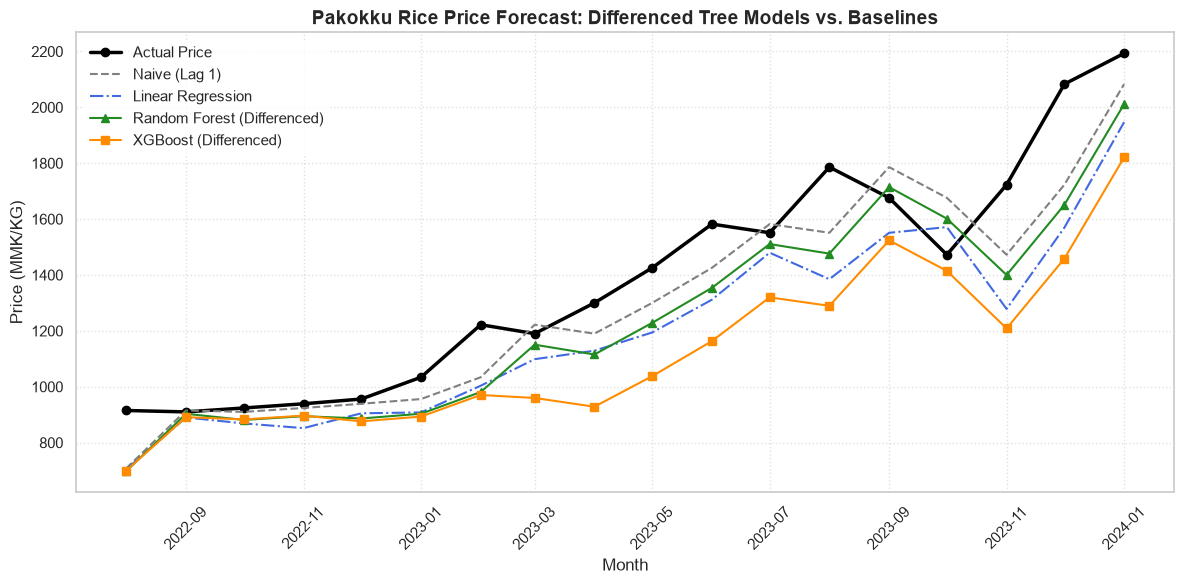

In [137]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Re-fit and predict using your dataset
dataset = df_full_eval  # Change to df_compact_eval if needed

df_stat = dataset.copy()
y_diff = df_stat["monthly_price"] - df_stat["lag_1"]
price_cols = [c for c in df_stat.columns if c.startswith(("lag_", "roll_mean_", "roll_min_", "roll_max_")) and c != "lag_1"]

for col in price_cols:
    df_stat[f"{col}_diff"] = df_stat[col] - df_stat["lag_1"]

raw_level_cols = ["monthly_price", "lag_1"] + price_cols
X_stat = df_stat.drop(columns=raw_level_cols)

X_tr = X_stat.loc[:train_end_date]
y_tr = y_diff.loc[:train_end_date]
X_va = X_stat.loc[val_start_date:val_end_date]
y_va_actual = dataset.loc[val_start_date:val_end_date, "monthly_price"]
lag1_va = dataset.loc[val_start_date:val_end_date, "lag_1"]

# Train differenced estimators
rf_diff = RandomForestRegressor(n_estimators=200, max_depth=4, min_samples_leaf=3, random_state=42)
xgb_diff = XGBRegressor(n_estimators=100, learning_rate=0.03, max_depth=2, subsample=0.8, random_state=42)

rf_diff.fit(X_tr, y_tr)
xgb_diff.fit(X_tr, y_tr)

pred_rf_diff = lag1_va + rf_diff.predict(X_va)
pred_xgb_diff = lag1_va + xgb_diff.predict(X_va)

# 2. Build the plot DataFrame using y_va_actual.index (fix for the TypeError)
plot_df = pd.DataFrame({
    "Actual Price": y_va_actual,
    "Naive (Lag 1)": lag1_va,
    "Linear Regression": linear_predictions,  # Assumes this exists from previous cells
    "Random Forest (Diff)": pred_rf_diff,
    "XGBoost (Diff)": pred_xgb_diff
}, index=y_va_actual.index)

# 3. Plotting the results
plt.figure(figsize=(12, 6))
# Convert period index to string or timestamp if matplotlib complains about PeriodIndex formatting
x_index = plot_df.index.to_timestamp() if hasattr(plot_df.index, "to_timestamp") else plot_df.index

plt.plot(x_index, plot_df["Actual Price"], label="Actual Price", color="black", linewidth=2.5, marker="o")
plt.plot(x_index, plot_df["Naive (Lag 1)"], label="Naive (Lag 1)", linestyle="--", color="gray")
plt.plot(x_index, plot_df["Linear Regression"], label="Linear Regression", linestyle="-.", color="royalblue")
plt.plot(x_index, plot_df["Random Forest (Diff)"], label="Random Forest (Differenced)", color="forestgreen", marker="^")
plt.plot(x_index, plot_df["XGBoost (Diff)"], label="XGBoost (Differenced)", color="darkorange", marker="s")

plt.title("Pakokku Rice Price Forecast: Differenced Tree Models vs. Baselines", fontsize=14, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Price (MMK/KG)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
plt.show()